In [1]:
'''Analyze confusion matrices in detail, calculating false positive/negative rates and
assessing model misclassification patterns to diagnose systematic prediction errors and 
inform model refinement.'''

'Analyze confusion matrices in detail, calculating false positive/negative rates and\nassessing model misclassification patterns to diagnose systematic prediction errors and \ninform model refinement.'

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (confusion_matrix,ConfusionMatrixDisplay,accuracy_score,precision_score,recall_score,f1_score,classification_report,roc_auc_score)

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

print("all libraries imported successfully")

all libraries imported successfully


In [4]:
# load dataset
df = pd.read_csv("global_pharmacy_sales_data.csv")

print("dataset shape:", df.shape)
display(df.head())

print("\ndataset information:")
df.info()

print("\nmissing values:")
display(df.isnull().sum())

print("\nduplicate records:", df.duplicated().sum())

print("\ntarget distribution:")
display(df['covid_flag'].value_counts())

dataset shape: (177990, 14)


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0



dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177990 entries, 0 to 177989
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   date                   177990 non-null  object 
 1   year                   177990 non-null  int64  
 2   month                  177990 non-null  int64  
 3   day                    177990 non-null  int64  
 4   region                 177990 non-null  object 
 5   country                177990 non-null  object 
 6   category               177990 non-null  object 
 7   medicine               177990 non-null  object 
 8   age_group              177990 non-null  object 
 9   units_sold             177990 non-null  int64  
 10  unit_price             177990 non-null  float64
 11  stock_level            177990 non-null  int64  
 12  expiry_days_remaining  177990 non-null  int64  
 13  covid_flag             177990 non-null  int64  
dtypes: float64(1),

date                     0
year                     0
month                    0
day                      0
region                   0
country                  0
category                 0
medicine                 0
age_group                0
units_sold               0
unit_price               0
stock_level              0
expiry_days_remaining    0
covid_flag               0
dtype: int64


duplicate records: 2630

target distribution:


covid_flag
0    118627
1     59363
Name: count, dtype: int64

In [5]:
# define target variable
target = 'covid_flag'

# remove date-derived variables to prevent target leakage
leakage_columns = ['date', 'year', 'month', 'day']

# prepare features and target
X = df.drop(columns=[target] + leakage_columns, errors='ignore')
y = df[target]

# identify numerical and categorical columns automatically
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("numerical features:", numeric_features)
print("\ncategorical features:", categorical_features)

print("\ntarget classes:")
print(y.value_counts())

# validate classification target
if y.nunique() != 2:
    raise ValueError("the selected target must contain exactly two classes")

# split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\ntraining records:", X_train.shape[0])
print("testing records:", X_test.shape[0])

numerical features: ['units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining']

categorical features: ['region', 'country', 'category', 'medicine', 'age_group']

target classes:
covid_flag
0    118627
1     59363
Name: count, dtype: int64

training records: 142392
testing records: 35598


In [6]:
# numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("automatic preprocessing pipeline created")

automatic preprocessing pipeline created


In [7]:
# define classification models
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
}

# train models and store predictions
trained_models = {}
predictions = {}
probabilities = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    # generate predictions
    y_pred = pipeline.predict(X_test)

    # generate probability scores
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    trained_models[name] = pipeline
    predictions[name] = y_pred
    probabilities[name] = y_prob

    print(f"{name} training completed")

print("\nall classification models trained successfully")

Logistic Regression training completed
Random Forest training completed

all classification models trained successfully


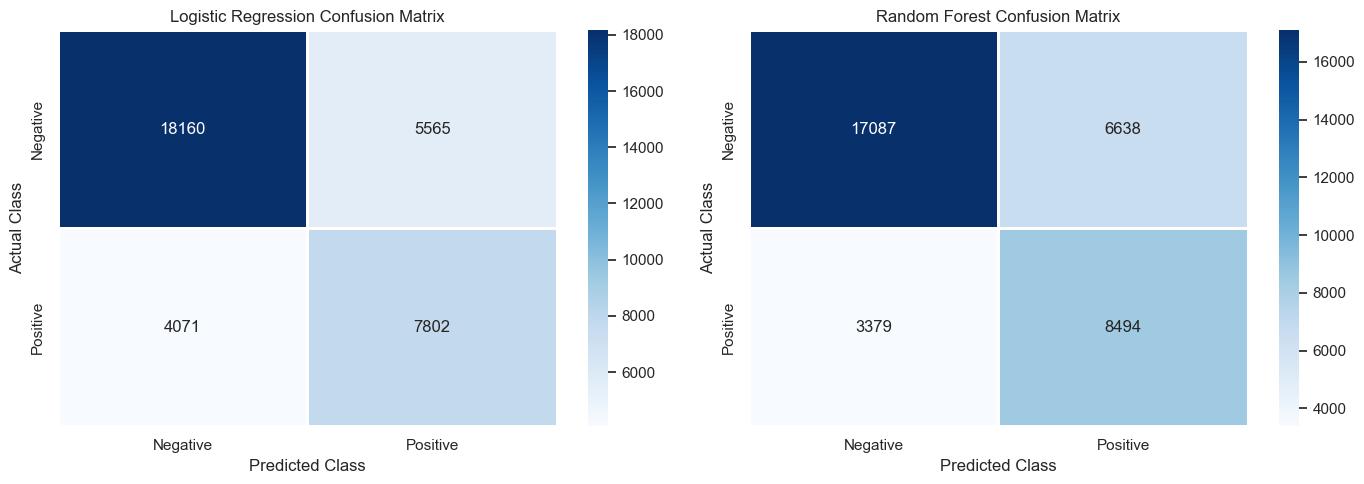

In [8]:
# generate confusion matrices for all models
fig, axes = plt.subplots(
    1,
    len(trained_models),
    figsize=(14, 5)
)

for ax, (name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        linewidths=1,
        xticklabels=['Negative', 'Positive'],
        yticklabels=['Negative', 'Positive'],
        ax=ax
    )

    ax.set_title(f'{name} Confusion Matrix')
    ax.set_xlabel('Predicted Class')
    ax.set_ylabel('Actual Class')

plt.tight_layout()
plt.show()

In [9]:
# calculate detailed classification metrics
results = []

for name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    # calculate error rates
    fpr = fp / (fp + tn) if (fp + tn) else 0
    fnr = fn / (fn + tp) if (fn + tp) else 0

    # calculate true prediction rates
    tpr = tp / (tp + fn) if (tp + fn) else 0
    tnr = tn / (tn + fp) if (tn + fp) else 0

    # calculate model performance
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    auc = roc_auc_score(
        y_test,
        probabilities[name]
    )

    results.append({
        'Model': name,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'FPR': fpr,
        'FNR': fnr,
        'TPR': tpr,
        'TNR': tnr,
        'ROC AUC': auc
    })

metrics_df = pd.DataFrame(results)

print("detailed model evaluation:")
display(metrics_df.round(4))

detailed model evaluation:


,Model,TN,FP,FN,TP,Accuracy,Precision,Recall,F1 Score,FPR,FNR,TPR,TNR,ROC AUC
0,Logistic Regression,18160,5565,4071,7802,0.7293,0.5837,0.6571,0.6182,0.2346,0.3429,0.6571,0.7654,0.7958
1,Random Forest,17087,6638,3379,8494,0.7186,0.5613,0.7154,0.6291,0.2798,0.2846,0.7154,0.7202,0.7993


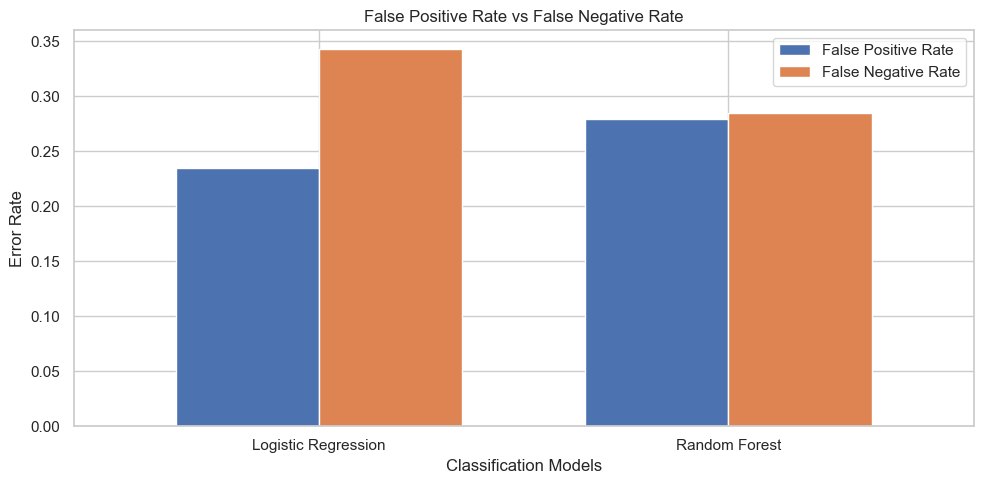

In [10]:
# compare false positive and false negative rates
error_comparison = metrics_df.set_index('Model')[
    ['FPR', 'FNR']
]

ax = error_comparison.plot(
    kind='bar',
    figsize=(10, 5),
    width=0.7
)

plt.title('False Positive Rate vs False Negative Rate')
plt.xlabel('Classification Models')
plt.ylabel('Error Rate')
plt.xticks(rotation=0)
plt.legend(['False Positive Rate', 'False Negative Rate'])
plt.tight_layout()
plt.show()

In [11]:
# create detailed misclassification records
misclassification_results = {}

for name, y_pred in predictions.items():

    error_data = X_test.copy()

    error_data['actual'] = y_test.values
    error_data['predicted'] = y_pred

    # identify incorrect predictions
    error_data['error_type'] = np.select(
        [
            (error_data['actual'] == 0) &
            (error_data['predicted'] == 1),

            (error_data['actual'] == 1) &
            (error_data['predicted'] == 0)
        ],
        [
            'false positive',
            'false negative'
        ],
        default='correct prediction'
    )

    misclassification_results[name] = error_data

    print(f"\n{name} misclassification summary:")

    display(
        error_data['error_type'].value_counts().to_frame(
            'number of records'
        )
    )

    print("incorrect prediction examples:")

    display(
        error_data[
            error_data['error_type'] != 'correct prediction'
        ].head(10)
    )


Logistic Regression misclassification summary:


,number of records
error_type,
correct prediction,25962
false positive,5565
false negative,4071


incorrect prediction examples:


,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,actual,predicted,error_type
169701,South Asia,India,Chronic,Metformin,46-65,559,32.13,4248,429,0,1,false positive
41220,North America,Canada,Chronic,Metformin,0-12,518,88.18,4292,629,0,1,false positive
13570,South Asia,India,Antipyretic,Ibuprofen,13-25,256,53.34,4810,51,1,0,false negative
46972,South America,Brazil,Chronic,Metformin,0-12,519,33.87,4349,610,0,1,false positive
14795,Africa,Kenya,Cough_Cold,Cough Syrup,65+,614,49.57,4578,165,0,1,false positive
87924,East Asia,Japan,Antipyretic,Ibuprofen,26-45,577,11.88,4245,476,0,1,false positive
53879,East Asia,South Korea,Cough_Cold,Cetirizine,46-65,549,92.78,4567,31,0,1,false positive
44032,North America,Canada,Vitamin,Multivitamin,65+,451,78.52,4429,664,0,1,false positive
103871,North America,Canada,Chronic,Metformin,13-25,515,67.10,4422,249,0,1,false positive
172129,East Asia,China,Chronic,Amlodipine,46-65,383,47.79,4649,645,1,0,false negative



Random Forest misclassification summary:


,number of records
error_type,
correct prediction,25581
false positive,6638
false negative,3379


incorrect prediction examples:


,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,actual,predicted,error_type
169701,South Asia,India,Chronic,Metformin,46-65,559,32.13,4248,429,0,1,false positive
41220,North America,Canada,Chronic,Metformin,0-12,518,88.18,4292,629,0,1,false positive
13570,South Asia,India,Antipyretic,Ibuprofen,13-25,256,53.34,4810,51,1,0,false negative
40110,South America,Brazil,Antipyretic,Paracetamol,26-45,432,73.03,4764,312,0,1,false positive
46972,South America,Brazil,Chronic,Metformin,0-12,519,33.87,4349,610,0,1,false positive
14795,Africa,Kenya,Cough_Cold,Cough Syrup,65+,614,49.57,4578,165,0,1,false positive
87924,East Asia,Japan,Antipyretic,Ibuprofen,26-45,577,11.88,4245,476,0,1,false positive
148608,South Asia,India,Antipyretic,Ibuprofen,0-12,441,98.44,4479,357,0,1,false positive
116985,South America,Brazil,Vitamin,Vitamin C,13-25,429,37.77,4562,129,0,1,false positive
53879,East Asia,South Korea,Cough_Cold,Cetirizine,46-65,549,92.78,4567,31,0,1,false positive


In [12]:
# analyze misclassification patterns by category
def analyze_error_patterns(error_data, group_column):

    if group_column not in error_data.columns:
        return None

    grouped = error_data.groupby(group_column).apply(
        lambda group: pd.Series({

            'total_records': len(group),

            'false_positives': (
                group['error_type'] == 'false positive'
            ).sum(),

            'false_negatives': (
                group['error_type'] == 'false negative'
            ).sum(),

            'correct_predictions': (
                group['error_type'] == 'correct prediction'
            ).sum(),

            'misclassification_rate': (
                (group['error_type'] != 'correct prediction').mean()
            ),

            'fpr': (
                (group['error_type'] == 'false positive').sum() /
                max((group['actual'] == 0).sum(), 1)
            ),

            'fnr': (
                (group['error_type'] == 'false negative').sum() /
                max((group['actual'] == 1).sum(), 1)
            )
        })
    ).reset_index()

    return grouped.sort_values(
        'misclassification_rate',
        ascending=False
    )


# select categorical features automatically
group_columns = [
    col for col in categorical_features
    if error_data[col].nunique() <= 50
]

# analyze each trained model
for name, error_data in misclassification_results.items():

    print(f"\n{'='*60}")
    print(f"systematic error analysis: {name}")
    print('='*60)

    for column in group_columns:

        print(f"\nerror analysis by {column}:")

        pattern_df = analyze_error_patterns(
            error_data,
            column
        )

        display(pattern_df.round(4))


systematic error analysis: Logistic Regression

error analysis by region:


,region,total_records,false_positives,false_negatives,correct_predictions,misclassification_rate,fpr,fnr
6,South America,4534.0,746.0,518.0,3270.0,0.2788,0.2469,0.3424
0,Africa,4503.0,713.0,518.0,3272.0,0.2734,0.2361,0.3493
5,Oceania,4419.0,682.0,521.0,3216.0,0.2722,0.2323,0.3513
2,Europe,4487.0,684.0,529.0,3274.0,0.2703,0.2275,0.3574
3,Middle East,4358.0,686.0,492.0,3180.0,0.2703,0.2372,0.3356
4,North America,4395.0,665.0,513.0,3217.0,0.2680,0.2276,0.3483
7,South Asia,4487.0,703.0,495.0,3289.0,0.2670,0.2365,0.3269
1,East Asia,4415.0,686.0,485.0,3244.0,0.2652,0.2322,0.3320



error analysis by country:


,country,total_records,false_positives,false_negatives,correct_predictions,misclassification_rate,fpr,fnr
17,UK,1479.0,243.0,185.0,1051.0,0.2894,0.2432,0.3854
16,UAE,2203.0,378.0,251.0,1574.0,0.2855,0.2610,0.3325
7,Germany,1503.0,233.0,195.0,1075.0,0.2848,0.2275,0.4071
10,Kenya,2229.0,369.0,260.0,1600.0,0.2822,0.2477,0.3518
0,Argentina,2190.0,369.0,245.0,1576.0,0.2804,0.2559,0.3275
8,India,1420.0,234.0,164.0,1022.0,0.2803,0.2481,0.3438
3,Brazil,2344.0,377.0,273.0,1694.0,0.2773,0.2388,0.3569
1,Australia,2234.0,359.0,256.0,1619.0,0.2753,0.2354,0.3611
9,Japan,1443.0,236.0,159.0,1048.0,0.2737,0.2423,0.3390
18,USA,2179.0,310.0,282.0,1587.0,0.2717,0.2177,0.3735



error analysis by category:


...

,category,total_records,false_positives,false_negatives,correct_predictions,misclassification_rate,fpr,fnr
3,Cough_Cold,6987.0,1329.0,689.0,4969.0,0.2888,0.2847,0.2971
1,Antipyretic,7095.0,1336.0,685.0,5074.0,0.2848,0.2850,0.2846
4,Vitamin,7179.0,1358.0,677.0,5144.0,0.2835,0.2809,0.2887
2,Chronic,7128.0,1306.0,672.0,5150.0,0.2775,0.2752,0.2821
0,Antibiotic,7209.0,1309.0,656.0,5244.0,0.2726,0.2733,0.2711



error analysis by medicine:


,medicine,total_records,false_positives,false_negatives,correct_predictions,misclassification_rate,fpr,fnr
3,Cetirizine,3489.0,663.0,355.0,2471.0,0.2918,0.2871,0.3008
7,Multivitamin,3534.0,699.0,323.0,2512.0,0.2892,0.2938,0.2797
8,Paracetamol,3595.0,697.0,334.0,2564.0,0.2868,0.2920,0.2765
4,Cough Syrup,3498.0,666.0,334.0,2498.0,0.2859,0.2823,0.2932
5,Ibuprofen,3500.0,639.0,351.0,2510.0,0.2829,0.2777,0.2927
0,Amlodipine,3563.0,647.0,349.0,2567.0,0.2795,0.2749,0.2887
9,Vitamin C,3645.0,659.0,354.0,2632.0,0.2779,0.2684,0.2975
6,Metformin,3565.0,659.0,323.0,2583.0,0.2755,0.2755,0.2754
2,Azithromycin,3647.0,673.0,325.0,2649.0,0.2736,0.2778,0.2655
1,Amoxicillin,3562.0,636.0,331.0,2595.0,0.2715,0.2688,0.2768



error analysis by age_group:


,age_group,total_records,false_positives,false_negatives,correct_predictions,misclassification_rate,fpr,fnr
3,46-65,7087.0,1372.0,677.0,5038.0,0.2891,0.2903,0.2867
2,26-45,7065.0,1332.0,661.0,5072.0,0.2821,0.2837,0.2789
1,13-25,7020.0,1255.0,717.0,5048.0,0.2809,0.2672,0.3087
4,65+,7258.0,1365.0,655.0,5238.0,0.2783,0.2853,0.2649
0,0-12,7168.0,1314.0,669.0,5185.0,0.2766,0.2725,0.2852


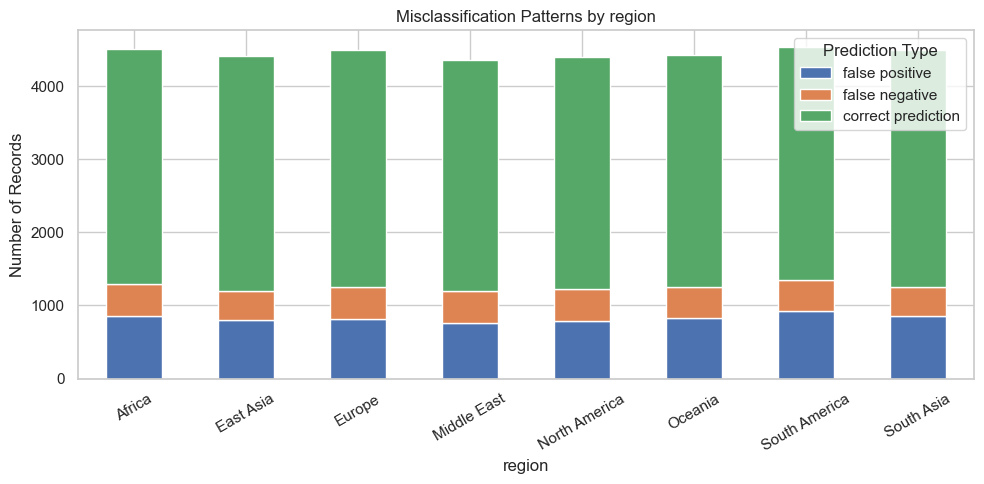

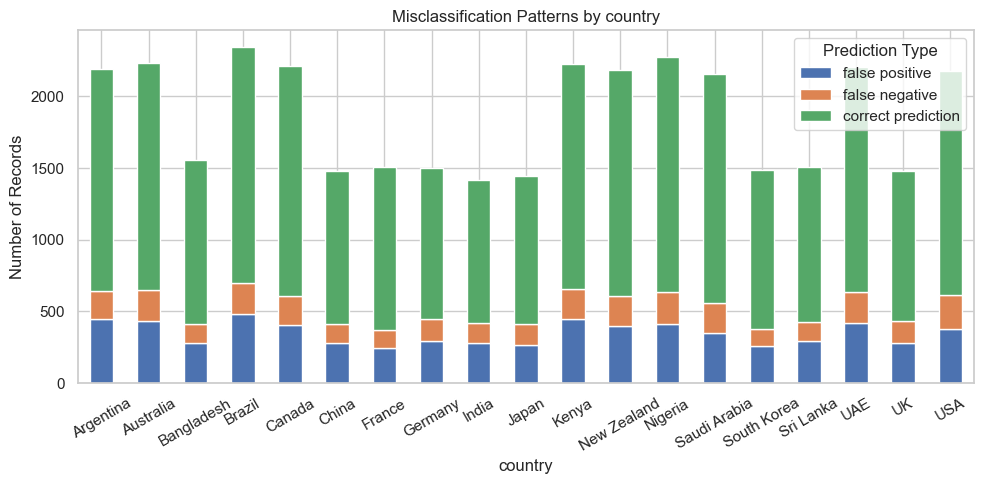

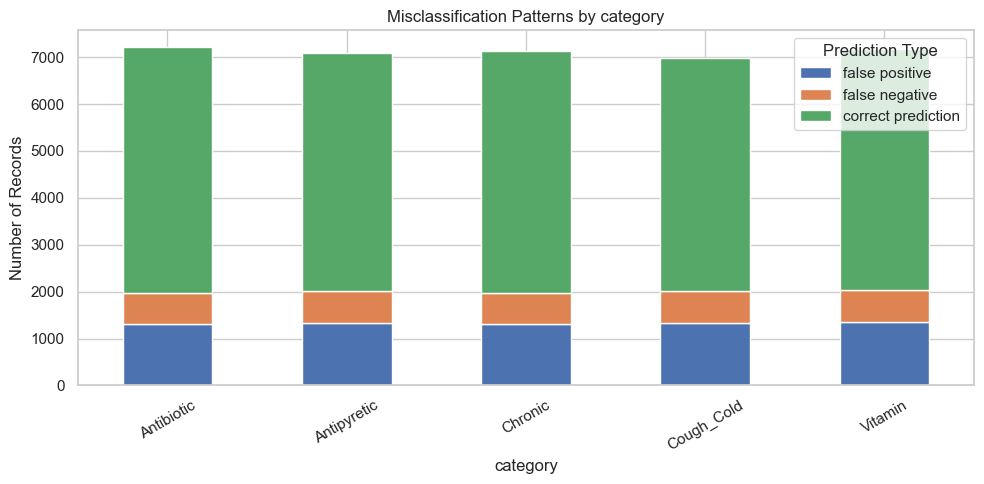

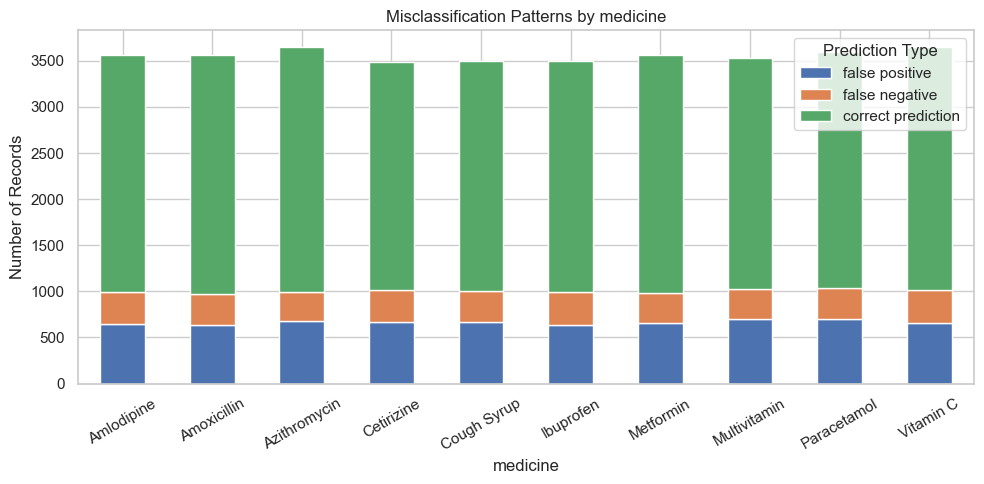

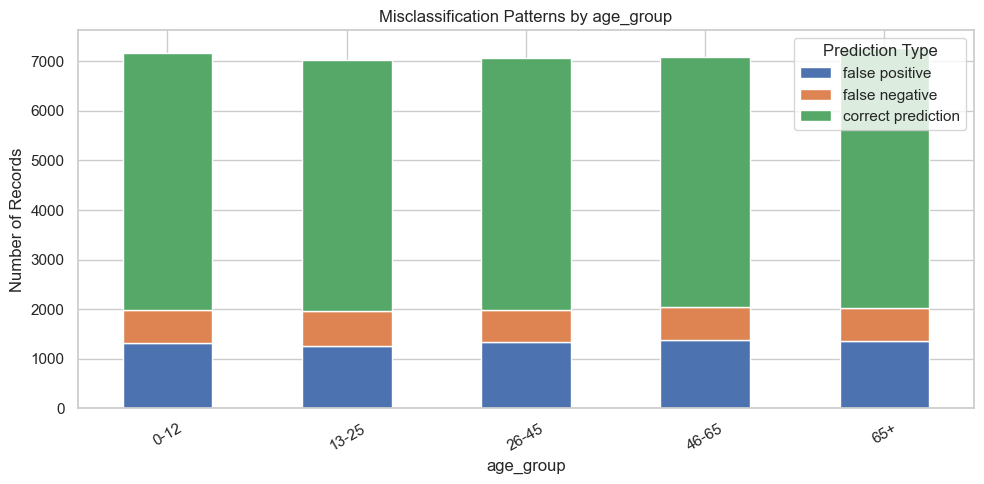

In [13]:
# visualize error patterns for the selected model
best_model_name = metrics_df.sort_values(
    'F1 Score',
    ascending=False
).iloc[0]['Model']

best_errors = misclassification_results[best_model_name]

for column in group_columns:

    error_counts = pd.crosstab(
        best_errors[column],
        best_errors['error_type']
    )

    error_counts = error_counts.reindex(
        columns=[
            'false positive',
            'false negative',
            'correct prediction'
        ],
        fill_value=0
    )

    error_counts.plot(
        kind='bar',
        stacked=True,
        figsize=(10, 5)
    )

    plt.title(f'Misclassification Patterns by {column}')
    plt.xlabel(column)
    plt.ylabel('Number of Records')
    plt.xticks(rotation=30)
    plt.legend(title='Prediction Type')
    plt.tight_layout()
    plt.show()

In [14]:
# generate detailed classification reports
for name, y_pred in predictions.items():

    print("\n", "="*55)
    print("classification report:", name)
    print("="*55)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=['negative', 'positive'],
            zero_division=0
        )
    )


classification report: Logistic Regression
              precision    recall  f1-score   support

    negative       0.82      0.77      0.79     23725
    positive       0.58      0.66      0.62     11873

    accuracy                           0.73     35598
   macro avg       0.70      0.71      0.70     35598
weighted avg       0.74      0.73      0.73     35598


classification report: Random Forest
              precision    recall  f1-score   support

    negative       0.83      0.72      0.77     23725
    positive       0.56      0.72      0.63     11873

    accuracy                           0.72     35598
   macro avg       0.70      0.72      0.70     35598
weighted avg       0.74      0.72      0.73     35598



top 15 important features:


,Feature,Importance
0,num__units_sold,0.539839
2,num__stock_level,0.292766
1,num__unit_price,0.050883
3,num__expiry_days_remaining,0.049362
48,cat__age_group_26-45,0.003694
49,cat__age_group_46-65,0.003614
47,cat__age_group_13-25,0.003600
46,cat__age_group_0-12,0.003595
50,cat__age_group_65+,0.003529
33,cat__category_Chronic,0.001640


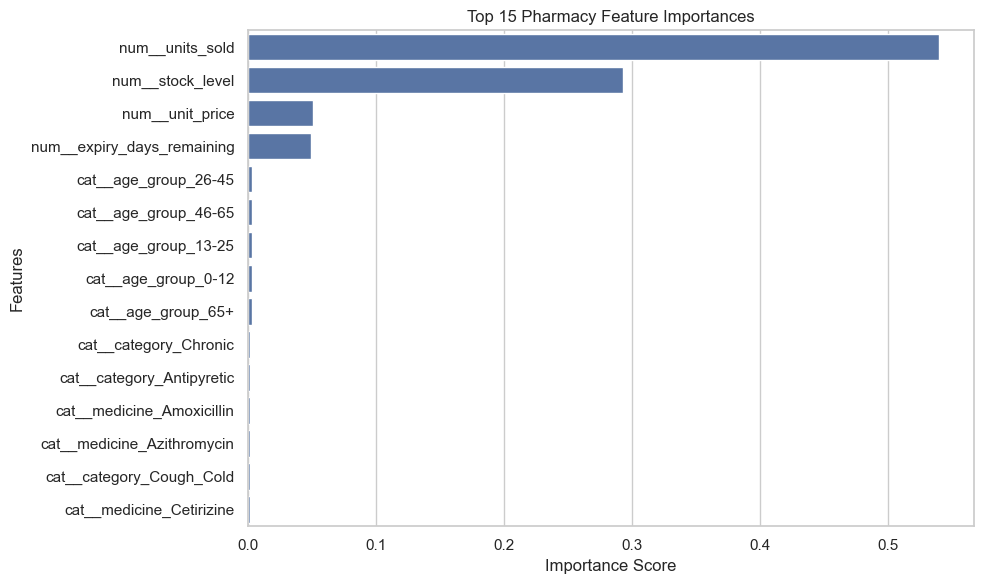

In [15]:
# extract random forest feature importance
rf_pipeline = trained_models['Random Forest']

# retrieve transformed feature names
feature_names = rf_pipeline.named_steps[
    'preprocessor'
].get_feature_names_out()

importance_values = rf_pipeline.named_steps[
    'classifier'
].feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance_values
}).sort_values(
    'Importance',
    ascending=False
)

print("top 15 important features:")

display(importance_df.head(15))

# visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Pharmacy Feature Importances')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [16]:
# compare models using multiple performance criteria
comparison = metrics_df.sort_values(
    by=['F1 Score', 'ROC AUC'],
    ascending=False
).reset_index(drop=True)

print("final model comparison:")

display(comparison.round(4))

# select the best model using f1 score
best_result = comparison.iloc[0]

print("\n", "="*55)
print("FINAL MODEL DIAGNOSIS")
print("="*55)

print("best model:", best_result['Model'])

print("accuracy:", round(best_result['Accuracy'], 4))
print("precision:", round(best_result['Precision'], 4))
print("recall:", round(best_result['Recall'], 4))
print("f1 score:", round(best_result['F1 Score'], 4))
print("roc auc:", round(best_result['ROC AUC'], 4))

print("false positive rate:", round(best_result['FPR'], 4))
print("false negative rate:", round(best_result['FNR'], 4))

print("\nmisclassification diagnosis:")

if best_result['FPR'] > best_result['FNR']:
    print("the model produces relatively more false positive errors.")

elif best_result['FNR'] > best_result['FPR']:
    print("the model produces relatively more false negative errors.")

else:
    print("both false positive and false negative rates are equal.")

print("\nmodel refinement recommendations:")

if best_result['FPR'] > 0.10:
    print("- investigate false positive predictions and improve specificity.")

if best_result['FNR'] > 0.10:
    print("- investigate false negative predictions and improve recall.")

if best_result['F1 Score'] < 0.80:
    print("- investigate feature quality, model parameters and class balance.")

if best_result['FPR'] <= 0.10 and best_result['FNR'] <= 0.10:
    print("- both error rates are relatively low; continue monitoring.")

print("\ncomplete confusion matrix analysis finished.")

final model comparison:


,Model,TN,FP,FN,TP,Accuracy,Precision,Recall,F1 Score,FPR,FNR,TPR,TNR,ROC AUC
0,Random Forest,17087,6638,3379,8494,0.7186,0.5613,0.7154,0.6291,0.2798,0.2846,0.7154,0.7202,0.7993
1,Logistic Regression,18160,5565,4071,7802,0.7293,0.5837,0.6571,0.6182,0.2346,0.3429,0.6571,0.7654,0.7958



FINAL MODEL DIAGNOSIS
best model: Random Forest
accuracy: 0.7186
precision: 0.5613
recall: 0.7154
f1 score: 0.6291
roc auc: 0.7993
false positive rate: 0.2798
false negative rate: 0.2846

misclassification diagnosis:
the model produces relatively more false negative errors.

model refinement recommendations:
- investigate false positive predictions and improve specificity.
- investigate false negative predictions and improve recall.
- investigate feature quality, model parameters and class balance.

complete confusion matrix analysis finished.
